In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/UIT/MXH/ynhi2111")

for item in sorted(DRIVE_ROOT.iterdir()):
    item_type = "DIR " if item.is_dir() else "FILE"
    print(f"[{item_type}] {item.name}")

[DIR ] e1
[DIR ] e2


In [3]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/UIT/MXH/ynhi2111")

E1_DIR = DRIVE_ROOT / "e1"
E2_DATA_DIR = DRIVE_ROOT /"e2"

E1_CHECKPOINT = E1_DIR / "best_model.pt"
E1_MODEL_FILE = E1_DIR / "e1_multibranch.py"

EMBEDDINGS_FILE = E2_DATA_DIR / "honduras_tweet_embeddings.npy"
LABELS_FILE = E2_DATA_DIR / "honduras_labels.npy"
SPLITS_FILE = E2_DATA_DIR / "honduras_split_names.npy"
METADATA_FILE = E2_DATA_DIR / "honduras_account_metadata.csv"

CONFIG_FILE = E2_DATA_DIR / "honduras_embedding_config.json"
VALIDATION_FILE = E2_DATA_DIR / "honduras_embedding_validation.json"

In [4]:
required_files = {
    "E1 checkpoint": E1_CHECKPOINT,
    "E1 model source": E1_MODEL_FILE,
    "Honduras embeddings": EMBEDDINGS_FILE,
    "Honduras labels": LABELS_FILE,
    "Honduras splits": SPLITS_FILE,
    "Honduras metadata": METADATA_FILE,
    "Embedding config": CONFIG_FILE,
    "Embedding validation": VALIDATION_FILE
}

for name, path in required_files.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

[FOUND] E1 checkpoint: /content/drive/MyDrive/UIT/MXH/ynhi2111/e1/best_model.pt
[FOUND] E1 model source: /content/drive/MyDrive/UIT/MXH/ynhi2111/e1/e1_multibranch.py
[FOUND] Honduras embeddings: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/honduras_tweet_embeddings.npy
[FOUND] Honduras labels: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/honduras_labels.npy
[FOUND] Honduras splits: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/honduras_split_names.npy
[FOUND] Honduras metadata: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/honduras_account_metadata.csv
[FOUND] Embedding config: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/honduras_embedding_config.json
[FOUND] Embedding validation: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/honduras_embedding_validation.json


In [5]:
import numpy as np
import pandas as pd
import json
import torch

X = np.load(EMBEDDINGS_FILE)
y = np.load(LABELS_FILE)
splits = np.load(SPLITS_FILE)

metadata = pd.read_csv(METADATA_FILE)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    embedding_config = json.load(f)

with open(VALIDATION_FILE, "r", encoding="utf-8") as f:
    embedding_validation = json.load(f)

print("=== DATA SHAPES ===")
print("Embeddings:", X.shape)
print("Labels:", y.shape)
print("Splits:", splits.shape)
print("Metadata:", metadata.shape)

print("\n=== EMBEDDING CONFIG ===")
print(json.dumps(embedding_config, indent=2, ensure_ascii=False))

print("\n=== EMBEDDING VALIDATION ===")
print(json.dumps(embedding_validation, indent=2, ensure_ascii=False))

=== DATA SHAPES ===
Embeddings: (224685, 384)
Labels: (224685,)
Splits: (224685,)
Metadata: (224685, 6)

=== EMBEDDING CONFIG ===
{
  "model": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
  "model_revision": "e8f8c211226b894fcb81acc59f3b34ba3efd5f42",
  "device": "NVIDIA GeForce RTX 3050 6GB Laptop GPU",
  "batch_size_tweets": 128,
  "inference_dtype": "float16",
  "embedding_dtype": "float32",
  "versions": {
    "python": "3.11.9",
    "numpy": "1.26.4",
    "torch": "2.5.1+cu121",
    "transformers": "5.12.1"
  },
  "embedding_dim": 384,
  "label_mapping": {
    "0": "Bad",
    "1": "Good"
  },
  "split_names": [
    "train",
    "validation",
    "test"
  ],
  "account_order": "manifest CSV row order",
  "id_contract": "decimal strings, never parsed as floating-point",
  "max_tweets_per_account": 5,
  "max_tokens_per_tweet": 128,
  "selection": "evenly spaced inclusive indices in normalized JSONL order after cleaning",
  "pooling": "attention-masked token mean, th

In [6]:
print("=== DATA VALIDATION ===")

assert X.ndim == 2, "Embeddings must be a 2D array."
assert X.shape[1] == 384, "Expected embedding dimension = 384."
assert y.ndim == 1, "Labels must be a 1D array."
assert splits.ndim == 1, "Splits must be a 1D array."

assert len(X) == len(y) == len(splits) == len(metadata), (
    "Number of rows does not match across input files."
)

assert np.isfinite(X).all(), "Embeddings contain NaN or Inf."

print("Embedding dimension:", X.shape[1])
print("Number of accounts:", len(X))
print("NaN:", np.isnan(X).sum())
print("Inf:", np.isinf(X).sum())

print("\nData validation: PASSED")

=== DATA VALIDATION ===
Embedding dimension: 384
Number of accounts: 224685
NaN: 0
Inf: 0

Data validation: PASSED


In [7]:
print("=== LABEL DISTRIBUTION ===")

label_counts = pd.Series(y).value_counts().sort_index()
print(label_counts)

print("\n=== SPLIT DISTRIBUTION ===")

split_counts = pd.Series(splits).value_counts()
print(split_counts)

print("\n=== LABEL BY SPLIT ===")

distribution = pd.crosstab(
    pd.Series(splits, name="Split"),
    pd.Series(y, name="Label")
)

print(distribution)

=== LABEL DISTRIBUTION ===
0      1866
1    222819
Name: count, dtype: int64

=== SPLIT DISTRIBUTION ===
train         157279
test           44938
validation     22468
Name: count, dtype: int64

=== LABEL BY SPLIT ===
Label          0       1
Split                   
test         373   44565
train       1306  155973
validation   187   22281


In [8]:
checkpoint = torch.load(
    E1_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

print("=== CHECKPOINT STRUCTURE ===")

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:")

    for key in checkpoint.keys():
        print("-", key)

=== CHECKPOINT STRUCTURE ===
Checkpoint type: <class 'dict'>
Checkpoint keys:
- epoch
- model_state_dict
- optimizer_state_dict
- best_dev_macro_f1
- config


In [9]:
assert "model_state_dict" in checkpoint, (
    "Cannot find model_state_dict in E1 checkpoint."
)

state_dict = checkpoint["model_state_dict"]

print("=== TWEET BRANCH PARAMETERS ===")

tweet_branch_keys = [
    key for key in state_dict.keys()
    if "tweet_branch" in key.lower()
]

for key in tweet_branch_keys:
    print(f"{key}: {tuple(state_dict[key].shape)}")

assert len(tweet_branch_keys) > 0, (
    "No Tweet Branch parameters found. "
    "Need to inspect E1 model architecture and checkpoint naming."
)

=== TWEET BRANCH PARAMETERS ===
tweet_branch.0.weight: (128, 384)
tweet_branch.0.bias: (128,)
tweet_branch.1.weight: (128,)
tweet_branch.1.bias: (128,)


In [10]:
with open(E1_MODEL_FILE, "r", encoding="utf-8") as f:
    e1_source = f.read()

print(e1_source)

import torch
import torch.nn as nn
import torch.nn.functional as F


class E1MultiBranch(nn.Module):
    def __init__(
        self,
        tweet_dim=384,
        profile_text_dim=384,
        profile_struct_dim=15,
        neighbor_dim=768,
        branch_dim=128,
        fusion_dim=256,
        projection_dim=128,
        num_classes=2,
        dropout=0.3
    ):
        super().__init__()

        def make_branch(input_dim):
            return nn.Sequential(
                nn.Linear(input_dim, branch_dim),
                nn.LayerNorm(branch_dim),
                nn.GELU(),
                nn.Dropout(dropout)
            )

        self.tweet_branch = make_branch(tweet_dim)
        self.profile_text_branch = make_branch(profile_text_dim)
        self.profile_struct_branch = make_branch(profile_struct_dim)
        self.neighbor_branch = make_branch(neighbor_dim)

        self.fusion = nn.Sequential(
            nn.Linear(branch_dim * 4, fusion_dim),
            nn.LayerNorm(fusion_

In [11]:
print("=== METADATA COLUMNS ===")

print(metadata.columns.tolist())

print("\n=== METADATA FIRST 5 ROWS ===")

display(metadata.head())

print("\n=== METADATA DATA TYPES ===")

print(metadata.dtypes)

=== METADATA COLUMNS ===
['row_index', 'account_id', 'label', 'split', 'eligible_tweet_count', 'selected_tweet_count']

=== METADATA FIRST 5 ROWS ===


,row_index,account_id,label,split,eligible_tweet_count,selected_tweet_count
0,0,1000005746078216193,1,train,1,1
1,1,1000006078409650177,1,train,0,0
2,2,100001435,1,test,0,0
3,3,100001645,1,train,0,0
4,4,1000017357534883840,1,train,0,0



=== METADATA DATA TYPES ===
row_index                int64
account_id               int64
label                    int64
split                   object
eligible_tweet_count     int64
selected_tweet_count     int64
dtype: object


In [12]:
label_columns = [
    col for col in metadata.columns
    if "label" in col.lower()
]

print("Potential label columns:", label_columns)

Potential label columns: ['label']


In [13]:
#nếu có cột label chạy
for col in label_columns:
    print(f"\n=== {col} ===")

    print(
        pd.crosstab(
            metadata[col],
            pd.Series(y, name="array_label")
        )
    )


=== label ===
array_label     0       1
label                    
0            1866       0
1               0  222819


In [14]:
print(json.dumps(
    embedding_config,
    indent=2,
    ensure_ascii=False
))

{
  "model": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
  "model_revision": "e8f8c211226b894fcb81acc59f3b34ba3efd5f42",
  "device": "NVIDIA GeForce RTX 3050 6GB Laptop GPU",
  "batch_size_tweets": 128,
  "inference_dtype": "float16",
  "embedding_dtype": "float32",
  "versions": {
    "python": "3.11.9",
    "numpy": "1.26.4",
    "torch": "2.5.1+cu121",
    "transformers": "5.12.1"
  },
  "embedding_dim": 384,
  "label_mapping": {
    "0": "Bad",
    "1": "Good"
  },
  "split_names": [
    "train",
    "validation",
    "test"
  ],
  "account_order": "manifest CSV row order",
  "id_contract": "decimal strings, never parsed as floating-point",
  "max_tweets_per_account": 5,
  "max_tokens_per_tweet": 128,
  "selection": "evenly spaced inclusive indices in normalized JSONL order after cleaning",
  "pooling": "attention-masked token mean, then mean of tweet vectors without L2 normalization",
  "duplicate_policy": "Keep first same-ID occurrence if account and stripped t

In [15]:
print(json.dumps(
    embedding_validation,
    indent=2,
    ensure_ascii=False
))

{
  "normalized_rows": {
    "honduras_bad_normalized.jsonl": 137252,
    "honduras_good_normalized.jsonl": 1125578
  },
  "duplicate_and_text_audit": {
    "group_a_audited_ids": 5259,
    "group_a_count_mismatches": 0,
    "group_a_conflicting_ids_excluded": 0,
    "group_a_safe_duplicate_ids": 5259,
    "group_b_audited_ids": 4,
    "group_b_count_mismatches": 0,
    "group_b_conflicting_ids_excluded": 4,
    "group_b_safe_duplicate_ids": 0,
    "duplicate_rows_collapsed": 7282,
    "conflicting_ids_excluded": 390,
    "conflicting_rows_excluded": 1364,
    "conflicting_ids_outside_audit": 386,
    "cross_split_text_groups_excluded": 34474,
    "cross_split_tweet_rows_excluded": 959205,
    "repeated_text_within_account_excluded": 19771
  },
  "accounts": 224685,
  "labels_by_split": {
    "train": {
      "Good": 155973,
      "Bad": 1306
    },
    "validation": {
      "Good": 22281,
      "Bad": 187
    },
    "test": {
      "Good": 44565,
      "Bad": 373
    }
  },
  "account

In [16]:
print("=== TWEET AVAILABILITY ===")

has_tweet = metadata["selected_tweet_count"].to_numpy() > 0
no_tweet = ~has_tweet

print("Accounts with tweets:", has_tweet.sum())
print("Accounts without tweets:", no_tweet.sum())

print("\n=== LABEL DISTRIBUTION BY TWEET AVAILABILITY ===")

availability_report = metadata.assign(
    tweet_status=np.where(has_tweet, "with_tweets", "without_tweets")
)

display(
    pd.crosstab(
        availability_report["label"],
        availability_report["tweet_status"],
        margins=True
    )
)

print("\n=== ZERO VECTOR CHECK ===")

zero_vector_mask = np.linalg.norm(X, axis=1) == 0

print("Zero vectors:", zero_vector_mask.sum())
print("Accounts with selected_tweet_count = 0:", no_tweet.sum())
print("Masks identical:", np.array_equal(zero_vector_mask, no_tweet))

assert np.array_equal(zero_vector_mask, no_tweet), (
    "Zero vector rows do not match accounts without selected tweets."
)

=== TWEET AVAILABILITY ===
Accounts with tweets: 46824
Accounts without tweets: 177861

=== LABEL DISTRIBUTION BY TWEET AVAILABILITY ===


tweet_status,with_tweets,without_tweets,All
label,,,
0,1726,140,1866
1,45098,177721,222819
All,46824,177861,224685



=== ZERO VECTOR CHECK ===
Zero vectors: 177861
Accounts with selected_tweet_count = 0: 177861
Masks identical: True


In [17]:
import hashlib

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

actual_checkpoint_hash = calculate_sha256(E1_CHECKPOINT)
expected_checkpoint_hash = embedding_config["e1_handoff"]["checkpoint_sha256"]

print("Expected:", expected_checkpoint_hash)
print("Actual:  ", actual_checkpoint_hash)
print("Match:   ", actual_checkpoint_hash == expected_checkpoint_hash)

Expected: 219c21ca894c6ea4bcd8a4ac009f0383880892aa0df665795e0ef8f880ce7394
Actual:   219c21ca894c6ea4bcd8a4ac009f0383880892aa0df665795e0ef8f880ce7394
Match:    True


In [18]:
#Tạo cohort có tweet và kiểm tra split
import numpy as np
import pandas as pd
import torch

from pathlib import Path

# Load dữ liệu nếu notebook chưa có các biến này
X = np.load(EMBEDDINGS_FILE, allow_pickle=False)
y = np.load(LABELS_FILE, allow_pickle=False)
splits = np.load(SPLITS_FILE, allow_pickle=False)

metadata = pd.read_csv(METADATA_FILE)

# Kiểm tra số lượng và thứ tự dữ liệu
assert len(X) == len(y) == len(splits) == len(metadata)
assert np.array_equal(y, metadata["label"].to_numpy())
assert np.array_equal(splits, metadata["split"].to_numpy())

# Chỉ giữ account có ít nhất một tweet
has_tweet = metadata["selected_tweet_count"].to_numpy() > 0

X_e2 = X[has_tweet].astype(np.float32)
y_e2 = y[has_tweet].astype(np.int64)
splits_e2 = splits[has_tweet]
metadata_e2 = metadata.loc[has_tweet].reset_index(drop=True)

# Kiểm tra không còn zero vector
zero_mask_e2 = np.linalg.norm(X_e2, axis=1) == 0

assert not zero_mask_e2.any()
assert set(np.unique(y_e2)) == {0, 1}
assert set(np.unique(splits_e2)) == {"train", "validation", "test"}

print("=== E2 COHORT ===")
print("X:", X_e2.shape)
print("y:", y_e2.shape)
print("Zero vectors:", zero_mask_e2.sum())

print("\n=== LABEL DISTRIBUTION ===")
display(pd.crosstab(
    pd.Series(splits_e2, name="split"),
    pd.Series(y_e2, name="label"),
    margins=True
))

=== E2 COHORT ===
X: (46824, 384)
y: (46824,)
Zero vectors: 0

=== LABEL DISTRIBUTION ===


label,0,1,All
split,,,
test,345,7383,7728
train,1209,34246,35455
validation,172,3469,3641
All,1726,45098,46824


In [19]:
#Tạo index cho từng tập dữ liệu
train_idx = np.where(splits_e2 == "train")[0]
val_idx = np.where(splits_e2 == "validation")[0]
test_idx = np.where(splits_e2 == "test")[0]

X_train, y_train = X_e2[train_idx], y_e2[train_idx]
X_val, y_val = X_e2[val_idx], y_e2[val_idx]
X_test, y_test = X_e2[test_idx], y_e2[test_idx]

print("Train:", X_train.shape, np.bincount(y_train, minlength=2))
print("Validation:", X_val.shape, np.bincount(y_val, minlength=2))
print("Test:", X_test.shape, np.bincount(y_test, minlength=2))

assert len(train_idx) == 35455
assert len(val_idx) == 3641
assert len(test_idx) == 7728

Train: (35455, 384) [ 1209 34246]
Validation: (3641, 384) [ 172 3469]
Test: (7728, 384) [ 345 7383]


In [20]:
#khai báo dataset
from torch.utils.data import Dataset, DataLoader

class HondurasTweetDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

train_dataset = HondurasTweetDataset(X_train, y_train)
val_dataset = HondurasTweetDataset(X_val, y_val)
test_dataset = HondurasTweetDataset(X_test, y_test)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 35455
Validation samples: 3641
Test samples: 7728


In [21]:
#Khởi tạo DataLoader
BATCH_SIZE = 128
SEED = 42

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Kiểm tra một batch
sample_X, sample_y = next(iter(train_loader))

print("Feature batch:", sample_X.shape)
print("Label batch:", sample_y.shape)
print("Label values:", torch.unique(sample_y).tolist())
print("Device available:", torch.cuda.is_available())

Feature batch: torch.Size([128, 384])
Label batch: torch.Size([128])
Label values: [0, 1]
Device available: True


In [22]:
#Khai báo E2TransferModel
import torch.nn as nn

class E2TransferModel(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()

        self.tweet_branch = nn.Sequential(
            nn.Linear(384, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        self.classifier = nn.Linear(128, 2)

        self.freeze_tweet_branch = False

    def forward(self, tweet):
        representation = self.tweet_branch(tweet)
        logits = self.classifier(representation)
        return logits

    def train(self, mode=True):
        super().train(mode)

        # Khi frozen, giữ Tweet Branch ở eval mode
        # để Dropout không làm thay đổi representation.
        if self.freeze_tweet_branch:
            self.tweet_branch.eval()

        return self

In [23]:
#Load Tweet Branch từ E1 checkpoint
checkpoint = torch.load(
    E1_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

assert "model_state_dict" in checkpoint

e1_state_dict = checkpoint["model_state_dict"]

tweet_branch_state = {
    key.replace("tweet_branch.", ""): value
    for key, value in e1_state_dict.items()
    if key.startswith("tweet_branch.")
}

print("E1 Tweet Branch parameters:")
for key, value in tweet_branch_state.items():
    print(f"{key}: {tuple(value.shape)}")

assert set(tweet_branch_state.keys()) == {
    "0.weight",
    "0.bias",
    "1.weight",
    "1.bias"
}

E1 Tweet Branch parameters:
0.weight: (128, 384)
0.bias: (128,)
1.weight: (128,)
1.bias: (128,)


In [24]:
#Khởi tạo ba cấu hình
def build_e2_model(config, device):
    model = E2TransferModel()

    if config in ["transfer", "frozen_transfer"]:
        model.tweet_branch.load_state_dict(
            tweet_branch_state,
            strict=True
        )

    if config == "frozen_transfer":
        for parameter in model.tweet_branch.parameters():
            parameter.requires_grad = False

        model.freeze_tweet_branch = True

    elif config not in ["scratch", "transfer"]:
        raise ValueError(f"Unknown config: {config}")

    return model.to(device)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

scratch_model = build_e2_model("scratch", device)
transfer_model = build_e2_model("transfer", device)
frozen_model = build_e2_model("frozen_transfer", device)

print("Device:", device)
print("\n=== TRAINABLE PARAMETERS ===")

for name, model in [
    ("Scratch", scratch_model),
    ("Transfer", transfer_model),
    ("Frozen Transfer", frozen_model)
]:
    trainable = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    total = sum(parameter.numel() for parameter in model.parameters())

    print(f"{name}: {trainable:,}/{total:,}")

Device: cuda

=== TRAINABLE PARAMETERS ===
Scratch: 49,794/49,794
Transfer: 49,794/49,794
Frozen Transfer: 258/49,794


In [25]:
#Kiểm tra forward pass
sample_X = sample_X.to(device)

for name, model in [
    ("Scratch", scratch_model),
    ("Transfer", transfer_model),
    ("Frozen Transfer", frozen_model)
]:
    model.eval()

    with torch.no_grad():
        logits = model(sample_X)

    print(f"{name}: {tuple(logits.shape)}")

    assert logits.shape == (BATCH_SIZE, 2)

Scratch: (128, 2)
Transfer: (128, 2)
Frozen Transfer: (128, 2)


In [26]:
#Cố định seed và tính class weights
import os
import random
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEED = 42
set_seed(SEED)

# Chỉ tính từ tập Train
class_counts = np.bincount(y_train, minlength=2)
total_train = len(y_train)

class_weights = np.sqrt(
    total_train / (2.0 * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Class counts [Bad, Good]:", class_counts)
print("Class weights [Bad, Good]:", class_weights.cpu().numpy())

assert class_counts[0] == 1209
assert class_counts[1] == 34246
assert torch.isfinite(class_weights).all()

Class counts [Bad, Good]: [ 1209 34246]
Class weights [Bad, Good]: [3.8292224  0.71948016]


In [27]:
#Khai báo hàm đánh giá trên Validation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

import torch.nn.functional as F

def evaluate_model(model, data_loader, criterion=None):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    total_loss = 0.0

    with torch.no_grad():
        for features, labels in data_loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = model(features)

            if criterion is not None:
                loss = criterion(logits, labels)
                total_loss += loss.item() * labels.size(0)

            probabilities = F.softmax(logits, dim=1)
            predictions = torch.argmax(logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_predictions)
    y_prob = np.asarray(all_probabilities)

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "bad_precision": precision_score(
            y_true, y_pred, pos_label=0, zero_division=0
        ),
        "bad_recall": recall_score(
            y_true, y_pred, pos_label=0, zero_division=0
        ),
        "bad_f1": f1_score(
            y_true, y_pred, pos_label=0, zero_division=0
        ),
        "bad_ap": average_precision_score(
            (y_true == 0).astype(int),
            y_prob[:, 0]
        ),
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).tolist()
    }

    if criterion is not None:
        metrics["loss"] = total_loss / len(data_loader.dataset)

    return metrics

In [28]:
#Khai báo hàm training và Early Stopping
import copy
import json
from pathlib import Path
from torch.optim import AdamW

E2_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results"
)

E2_CHECKPOINT_DIR = E2_OUTPUT_DIR / "checkpoints"
E2_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def train_one_model(config, max_epochs=30, patience=5):
    set_seed(SEED)

    model = build_e2_model(config, device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.0002,
        weight_decay=0.01
    )

    best_macro_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    history = []

    checkpoint_path = E2_CHECKPOINT_DIR / f"{config}_best.pt"

    for epoch in range(1, max_epochs + 1):
        model.train()

        total_train_loss = 0.0

        for features, labels in train_loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(features)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * labels.size(0)

        train_loss = total_train_loss / len(train_loader.dataset)

        val_metrics = evaluate_model(
            model,
            val_loader,
            criterion
        )

        current_f1 = val_metrics["macro_f1"]
        current_val_loss = val_metrics["loss"]

        improved = (
            current_f1 > best_macro_f1
            or (
                np.isclose(current_f1, best_macro_f1)
                and current_val_loss < best_val_loss
            )
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": current_val_loss,
            "val_macro_f1": current_f1,
            "val_bad_f1": val_metrics["bad_f1"],
            "val_bad_recall": val_metrics["bad_recall"],
            "val_bad_ap": val_metrics["bad_ap"]
        })

        print(
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {current_val_loss:.4f} | "
            f"Val Macro-F1: {current_f1:.4f} | "
            f"Bad F1: {val_metrics['bad_f1']:.4f} | "
            f"Bad Recall: {val_metrics['bad_recall']:.4f} | "
            f"Bad AP: {val_metrics['bad_ap']:.4f}"
        )

        if improved:
            best_macro_f1 = current_f1
            best_val_loss = current_val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "config": config,
                "seed": SEED,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_metrics": val_metrics,
                "class_weights": class_weights.cpu().tolist()
            }, checkpoint_path)

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}.")
            break

    # Lưu lịch sử training
    history_path = E2_OUTPUT_DIR / f"{config}_history.json"

    with open(history_path, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)

    # Load lại checkpoint tốt nhất
    best_checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(best_checkpoint["model_state_dict"])

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best Validation Macro-F1: {best_macro_f1:.4f}")
    print(f"Checkpoint saved: {checkpoint_path}")

    return model, history, best_checkpoint

In [29]:
#Chạy thử cấu hình Scratch
scratch_model, scratch_history, scratch_checkpoint = train_one_model(
    config="scratch",
    max_epochs=30,
    patience=5
)

print("\n=== BEST SCRATCH VALIDATION METRICS ===")

for key, value in scratch_checkpoint["val_metrics"].items():
    print(f"{key}: {value}")

Epoch 01/30 | Train Loss: 0.1566 | Val Loss: 0.0977 | Val Macro-F1: 0.9102 | Bad F1: 0.8291 | Bad Recall: 0.8605 | Bad AP: 0.9088
Epoch 02/30 | Train Loss: 0.0825 | Val Loss: 0.0847 | Val Macro-F1: 0.9117 | Bad F1: 0.8324 | Bad Recall: 0.8953 | Bad AP: 0.9311
Epoch 03/30 | Train Loss: 0.0651 | Val Loss: 0.0815 | Val Macro-F1: 0.9063 | Bad F1: 0.8226 | Bad Recall: 0.9302 | Bad AP: 0.9447
Epoch 04/30 | Train Loss: 0.0547 | Val Loss: 0.0707 | Val Macro-F1: 0.9357 | Bad F1: 0.8778 | Bad Recall: 0.9186 | Bad AP: 0.9486
Epoch 05/30 | Train Loss: 0.0475 | Val Loss: 0.0759 | Val Macro-F1: 0.9136 | Bad F1: 0.8364 | Bad Recall: 0.9360 | Bad AP: 0.9489
Epoch 06/30 | Train Loss: 0.0392 | Val Loss: 0.0681 | Val Macro-F1: 0.9263 | Bad F1: 0.8602 | Bad Recall: 0.9302 | Bad AP: 0.9554
Epoch 07/30 | Train Loss: 0.0333 | Val Loss: 0.0689 | Val Macro-F1: 0.9363 | Bad F1: 0.8789 | Bad Recall: 0.9070 | Bad AP: 0.9534
Epoch 08/30 | Train Loss: 0.0300 | Val Loss: 0.0678 | Val Macro-F1: 0.9466 | Bad F1: 0.898

In [31]:
#Chạy Transfer - Reset thứ tự shuffle về seed 42
train_loader.generator.manual_seed(SEED)

transfer_model, transfer_history, transfer_checkpoint = train_one_model(
    config="transfer",
    max_epochs=30,
    patience=5
)

print("\n=== BEST TRANSFER VALIDATION METRICS ===")

for key, value in transfer_checkpoint["val_metrics"].items():
    print(f"{key}: {value}")

Epoch 01/30 | Train Loss: 0.1905 | Val Loss: 0.1007 | Val Macro-F1: 0.9119 | Bad F1: 0.8324 | Bad Recall: 0.8663 | Bad AP: 0.9033
Epoch 02/30 | Train Loss: 0.0914 | Val Loss: 0.0901 | Val Macro-F1: 0.8972 | Bad F1: 0.8052 | Bad Recall: 0.9012 | Bad AP: 0.9289
Epoch 03/30 | Train Loss: 0.0740 | Val Loss: 0.0820 | Val Macro-F1: 0.9207 | Bad F1: 0.8493 | Bad Recall: 0.9012 | Bad AP: 0.9352
Epoch 04/30 | Train Loss: 0.0624 | Val Loss: 0.0779 | Val Macro-F1: 0.9135 | Bad F1: 0.8360 | Bad Recall: 0.9186 | Bad AP: 0.9447
Epoch 05/30 | Train Loss: 0.0546 | Val Loss: 0.0757 | Val Macro-F1: 0.9373 | Bad F1: 0.8807 | Bad Recall: 0.9012 | Bad AP: 0.9454
Epoch 06/30 | Train Loss: 0.0474 | Val Loss: 0.0748 | Val Macro-F1: 0.9370 | Bad F1: 0.8800 | Bad Recall: 0.8953 | Bad AP: 0.9479
Epoch 07/30 | Train Loss: 0.0420 | Val Loss: 0.0714 | Val Macro-F1: 0.9286 | Bad F1: 0.8643 | Bad Recall: 0.9070 | Bad AP: 0.9504
Epoch 08/30 | Train Loss: 0.0355 | Val Loss: 0.0688 | Val Macro-F1: 0.9423 | Bad F1: 0.890

In [32]:
#Chạy Frozen Transfer - Reset thứ tự shuffle về seed 42
train_loader.generator.manual_seed(SEED)

frozen_model, frozen_history, frozen_checkpoint = train_one_model(
    config="frozen_transfer",
    max_epochs=30,
    patience=5
)

print("\n=== BEST FROZEN TRANSFER VALIDATION METRICS ===")

for key, value in frozen_checkpoint["val_metrics"].items():
    print(f"{key}: {value}")

Epoch 01/30 | Train Loss: 0.4377 | Val Loss: 0.3216 | Val Macro-F1: 0.5183 | Bad F1: 0.0622 | Bad Recall: 0.0349 | Bad AP: 0.2615
Epoch 02/30 | Train Loss: 0.3144 | Val Loss: 0.2760 | Val Macro-F1: 0.6353 | Bad F1: 0.2951 | Bad Recall: 0.2093 | Bad AP: 0.3613
Epoch 03/30 | Train Loss: 0.2726 | Val Loss: 0.2515 | Val Macro-F1: 0.7072 | Bad F1: 0.4375 | Bad Recall: 0.3663 | Bad AP: 0.4549
Epoch 04/30 | Train Loss: 0.2465 | Val Loss: 0.2343 | Val Macro-F1: 0.7711 | Bad F1: 0.5627 | Bad Recall: 0.5349 | Bad AP: 0.5323
Epoch 05/30 | Train Loss: 0.2276 | Val Loss: 0.2194 | Val Macro-F1: 0.8065 | Bad F1: 0.6306 | Bad Recall: 0.6105 | Bad AP: 0.5912
Epoch 06/30 | Train Loss: 0.2132 | Val Loss: 0.2109 | Val Macro-F1: 0.8149 | Bad F1: 0.6480 | Bad Recall: 0.6744 | Bad AP: 0.6355
Epoch 07/30 | Train Loss: 0.2016 | Val Loss: 0.2014 | Val Macro-F1: 0.8276 | Bad F1: 0.6722 | Bad Recall: 0.7035 | Bad AP: 0.6630
Epoch 08/30 | Train Loss: 0.1921 | Val Loss: 0.1948 | Val Macro-F1: 0.8286 | Bad F1: 0.674

In [33]:
#Lưu riêng các checkpoint Seed 42
import shutil

for config in ["scratch", "transfer", "frozen_transfer"]:
    source_checkpoint = E2_CHECKPOINT_DIR / f"{config}_best.pt"
    target_checkpoint = E2_CHECKPOINT_DIR / f"{config}_seed42_best.pt"

    source_history = E2_OUTPUT_DIR / f"{config}_history.json"
    target_history = E2_OUTPUT_DIR / f"{config}_seed42_history.json"

    assert source_checkpoint.exists(), f"Missing: {source_checkpoint}"
    assert source_history.exists(), f"Missing: {source_history}"

    shutil.copy2(source_checkpoint, target_checkpoint)
    shutil.copy2(source_history, target_history)

    print(f"Saved: {target_checkpoint.name}")
    print(f"Saved: {target_history.name}")

Saved: scratch_seed42_best.pt
Saved: scratch_seed42_history.json
Saved: transfer_seed42_best.pt
Saved: transfer_seed42_history.json
Saved: frozen_transfer_seed42_best.pt
Saved: frozen_transfer_seed42_history.json


In [34]:
#Cập nhật hàm training hỗ trợ nhiều seeds
def train_one_model(config, seed=42, max_epochs=30, patience=5):
    set_seed(seed)
    train_loader.generator.manual_seed(seed)

    model = build_e2_model(config, device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.0002,
        weight_decay=0.01
    )

    best_macro_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    history = []

    checkpoint_path = (
        E2_CHECKPOINT_DIR / f"{config}_seed{seed}_best.pt"
    )

    for epoch in range(1, max_epochs + 1):
        model.train()
        total_train_loss = 0.0

        for features, labels in train_loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(features)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * labels.size(0)

        train_loss = total_train_loss / len(train_loader.dataset)

        val_metrics = evaluate_model(
            model,
            val_loader,
            criterion
        )

        current_f1 = val_metrics["macro_f1"]
        current_val_loss = val_metrics["loss"]

        improved = (
            current_f1 > best_macro_f1
            or (
                np.isclose(current_f1, best_macro_f1)
                and current_val_loss < best_val_loss
            )
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": current_val_loss,
            "val_macro_f1": current_f1,
            "val_bad_f1": val_metrics["bad_f1"],
            "val_bad_recall": val_metrics["bad_recall"],
            "val_bad_ap": val_metrics["bad_ap"]
        })

        print(
            f"Seed {seed} | {config} | "
            f"Epoch {epoch:02d}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {current_val_loss:.4f} | "
            f"Val Macro-F1: {current_f1:.4f} | "
            f"Bad F1: {val_metrics['bad_f1']:.4f} | "
            f"Bad Recall: {val_metrics['bad_recall']:.4f} | "
            f"Bad AP: {val_metrics['bad_ap']:.4f}"
        )

        if improved:
            best_macro_f1 = current_f1
            best_val_loss = current_val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save({
                "config": config,
                "seed": seed,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_metrics": val_metrics,
                "class_weights": class_weights.cpu().tolist()
            }, checkpoint_path)

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}.")
            break

    history_path = E2_OUTPUT_DIR / f"{config}_seed{seed}_history.json"

    with open(history_path, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)

    best_checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(best_checkpoint["model_state_dict"])

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best Validation Macro-F1: {best_macro_f1:.4f}")
    print(f"Checkpoint saved: {checkpoint_path}")

    return model, history, best_checkpoint

In [35]:
seed52_results = {}

for config in ["scratch", "transfer", "frozen_transfer"]:
    model, history, checkpoint = train_one_model(
        config=config,
        seed=52,
        max_epochs=30,
        patience=5
    )

    seed52_results[config] = {
        "model": model,
        "history": history,
        "checkpoint": checkpoint
    }

Seed 52 | scratch | Epoch 01/30 | Train Loss: 0.1762 | Val Loss: 0.0995 | Val Macro-F1: 0.9063 | Bad F1: 0.8219 | Bad Recall: 0.8721 | Bad AP: 0.9120
Seed 52 | scratch | Epoch 02/30 | Train Loss: 0.0847 | Val Loss: 0.0851 | Val Macro-F1: 0.9104 | Bad F1: 0.8303 | Bad Recall: 0.9244 | Bad AP: 0.9353
Seed 52 | scratch | Epoch 03/30 | Train Loss: 0.0682 | Val Loss: 0.0778 | Val Macro-F1: 0.9187 | Bad F1: 0.8457 | Bad Recall: 0.9244 | Bad AP: 0.9431
Seed 52 | scratch | Epoch 04/30 | Train Loss: 0.0574 | Val Loss: 0.0719 | Val Macro-F1: 0.9191 | Bad F1: 0.8466 | Bad Recall: 0.9302 | Bad AP: 0.9507
Seed 52 | scratch | Epoch 05/30 | Train Loss: 0.0487 | Val Loss: 0.0741 | Val Macro-F1: 0.9074 | Bad F1: 0.8247 | Bad Recall: 0.9302 | Bad AP: 0.9544
Seed 52 | scratch | Epoch 06/30 | Train Loss: 0.0421 | Val Loss: 0.0670 | Val Macro-F1: 0.9377 | Bad F1: 0.8815 | Bad Recall: 0.9302 | Bad AP: 0.9566
Seed 52 | scratch | Epoch 07/30 | Train Loss: 0.0363 | Val Loss: 0.0712 | Val Macro-F1: 0.9526 | Bad

In [36]:
seed62_results = {}

for config in ["scratch", "transfer", "frozen_transfer"]:
    model, history, checkpoint = train_one_model(
        config=config,
        seed=62,
        max_epochs=30,
        patience=5
    )

    seed62_results[config] = {
        "model": model,
        "history": history,
        "checkpoint": checkpoint
    }

Seed 62 | scratch | Epoch 01/30 | Train Loss: 0.1829 | Val Loss: 0.0971 | Val Macro-F1: 0.8980 | Bad F1: 0.8065 | Bad Recall: 0.8721 | Bad AP: 0.9115
Seed 62 | scratch | Epoch 02/30 | Train Loss: 0.0837 | Val Loss: 0.0805 | Val Macro-F1: 0.9171 | Bad F1: 0.8427 | Bad Recall: 0.9186 | Bad AP: 0.9386
Seed 62 | scratch | Epoch 03/30 | Train Loss: 0.0674 | Val Loss: 0.0789 | Val Macro-F1: 0.9302 | Bad F1: 0.8674 | Bad Recall: 0.9128 | Bad AP: 0.9379
Seed 62 | scratch | Epoch 04/30 | Train Loss: 0.0554 | Val Loss: 0.0684 | Val Macro-F1: 0.9319 | Bad F1: 0.8705 | Bad Recall: 0.9186 | Bad AP: 0.9521
Seed 62 | scratch | Epoch 05/30 | Train Loss: 0.0483 | Val Loss: 0.0751 | Val Macro-F1: 0.9452 | Bad F1: 0.8955 | Bad Recall: 0.8721 | Bad AP: 0.9498
Seed 62 | scratch | Epoch 06/30 | Train Loss: 0.0401 | Val Loss: 0.0650 | Val Macro-F1: 0.9442 | Bad F1: 0.8939 | Bad Recall: 0.9302 | Bad AP: 0.9559
Seed 62 | scratch | Epoch 07/30 | Train Loss: 0.0337 | Val Loss: 0.0634 | Val Macro-F1: 0.9399 | Bad

In [37]:
SEEDS = [42, 52, 62]

CONFIGS = [
    "scratch",
    "transfer",
    "frozen_transfer"
]

validation_rows = []

for seed in SEEDS:
    for config in CONFIGS:
        checkpoint_path = (
            E2_CHECKPOINT_DIR / f"{config}_seed{seed}_best.pt"
        )

        assert checkpoint_path.exists(), (
            f"Missing checkpoint: {checkpoint_path}"
        )

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )

        model = build_e2_model(config, device)
        model.load_state_dict(checkpoint["model_state_dict"])

        metrics = evaluate_model(model, val_loader)

        validation_rows.append({
            "seed": seed,
            "configuration": config,
            "best_epoch": checkpoint["epoch"],
            "accuracy": metrics["accuracy"],
            "macro_precision": metrics["macro_precision"],
            "macro_recall": metrics["macro_recall"],
            "macro_f1": metrics["macro_f1"],
            "bad_precision": metrics["bad_precision"],
            "bad_recall": metrics["bad_recall"],
            "bad_f1": metrics["bad_f1"],
            "bad_ap": metrics["bad_ap"]
        })

        print(
            f"Verified: {config}, seed={seed}, "
            f"epoch={checkpoint['epoch']}, "
            f"Macro-F1={metrics['macro_f1']:.4f}"
        )

validation_df = pd.DataFrame(validation_rows)

print("\n=== VALIDATION RESULTS BY SEED ===")
display(
    validation_df.sort_values(
        ["configuration", "seed"]
    ).reset_index(drop=True)
)

Verified: scratch, seed=42, epoch=28, Macro-F1=0.9688
Verified: transfer, seed=42, epoch=22, Macro-F1=0.9659
Verified: frozen_transfer, seed=42, epoch=13, Macro-F1=0.8598
Verified: scratch, seed=52, epoch=14, Macro-F1=0.9642
Verified: transfer, seed=52, epoch=14, Macro-F1=0.9664
Verified: frozen_transfer, seed=52, epoch=22, Macro-F1=0.8643
Verified: scratch, seed=62, epoch=12, Macro-F1=0.9634
Verified: transfer, seed=62, epoch=15, Macro-F1=0.9599
Verified: frozen_transfer, seed=62, epoch=29, Macro-F1=0.8643

=== VALIDATION RESULTS BY SEED ===


,seed,configuration,best_epoch,accuracy,macro_precision,macro_recall,macro_f1,bad_precision,bad_recall,bad_f1,bad_ap
0,42,frozen_transfer,13,0.972535,0.833289,0.891650,0.859781,0.676471,0.802326,0.734043,0.757632
1,52,frozen_transfer,22,0.973359,0.836807,0.897608,0.864329,0.682927,0.813953,0.742706,0.803466
2,62,frozen_transfer,29,0.972810,0.831451,0.905608,0.864252,0.671362,0.831395,0.742857,0.811670
3,42,scratch,28,0.994507,0.979694,0.958438,0.968798,0.963415,0.918605,0.940476,0.961208
4,52,scratch,14,0.993683,0.973600,0.955242,0.964220,0.951515,0.912791,0.931751,0.962192
5,62,scratch,12,0.993408,0.963387,0.963387,0.963387,0.930233,0.930233,0.930233,0.963558
6,42,transfer,22,0.993958,0.973889,0.958149,0.965872,0.951807,0.918605,0.934911,0.963603
7,52,transfer,14,0.993958,0.966438,0.966438,0.966438,0.936047,0.936047,0.936047,0.961430
8,62,transfer,15,0.992859,0.965102,0.954810,0.959892,0.934524,0.912791,0.923529,0.963688


In [38]:
#Tính mean ± standard deviation chính xác
metric_columns = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "bad_precision",
    "bad_recall",
    "bad_f1",
    "bad_ap"
]

summary_rows = []

for config in CONFIGS:
    subset = validation_df[
        validation_df["configuration"] == config
    ]

    row = {"configuration": config}

    for metric in metric_columns:
        row[f"{metric}_mean"] = subset[metric].mean()
        row[f"{metric}_std"] = subset[metric].std(ddof=1)

    summary_rows.append(row)

validation_summary = pd.DataFrame(summary_rows)

print("=== VALIDATION MEAN ± STD (3 SEEDS) ===")
display(validation_summary.round(4))

=== VALIDATION MEAN ± STD (3 SEEDS) ===


,configuration,accuracy_mean,accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,bad_precision_mean,bad_precision_std,bad_recall_mean,bad_recall_std,bad_f1_mean,bad_f1_std,bad_ap_mean,bad_ap_std
0,scratch,0.9939,0.0006,0.9722,0.0082,0.9590,0.0041,0.9655,0.0029,0.9484,0.0168,0.9205,0.0089,0.9342,0.0055,0.9623,0.0012
1,transfer,0.9936,0.0006,0.9685,0.0047,0.9598,0.0060,0.9641,0.0036,0.9408,0.0096,0.9225,0.0121,0.9315,0.0069,0.9629,0.0013
2,frozen_transfer,0.9729,0.0004,0.8338,0.0027,0.8983,0.0070,0.8628,0.0026,0.6769,0.0058,0.8159,0.0146,0.7399,0.0050,0.7909,0.0291


In [39]:
#Evaluate 9 checkpoints trên Test set
test_rows = []
test_confusion_matrices = {}

for seed in SEEDS:
    for config in CONFIGS:
        checkpoint_path = E2_CHECKPOINT_DIR / f"{config}_seed{seed}_best.pt"

        assert checkpoint_path.exists(), f"Missing checkpoint: {checkpoint_path}"

        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

        model = build_e2_model(config, device)
        model.load_state_dict(checkpoint["model_state_dict"])

        metrics = evaluate_model(model, test_loader)

        test_rows.append({
            "seed": seed,
            "configuration": config,
            "best_epoch": checkpoint["epoch"],
            "accuracy": metrics["accuracy"],
            "macro_precision": metrics["macro_precision"],
            "macro_recall": metrics["macro_recall"],
            "macro_f1": metrics["macro_f1"],
            "bad_precision": metrics["bad_precision"],
            "bad_recall": metrics["bad_recall"],
            "bad_f1": metrics["bad_f1"],
            "bad_ap": metrics["bad_ap"]
        })

        test_confusion_matrices[(config, seed)] = metrics["confusion_matrix"]

        print(
            f"Evaluated: {config}, seed={seed}, "
            f"epoch={checkpoint['epoch']}, "
            f"Macro-F1={metrics['macro_f1']:.4f}"
        )

test_df = pd.DataFrame(test_rows)

print("\n=== TEST RESULTS BY SEED ===")
display(
    test_df.sort_values(["configuration", "seed"]).reset_index(drop=True)
)

Evaluated: scratch, seed=42, epoch=28, Macro-F1=0.9632
Evaluated: transfer, seed=42, epoch=22, Macro-F1=0.9581
Evaluated: frozen_transfer, seed=42, epoch=13, Macro-F1=0.8498
Evaluated: scratch, seed=52, epoch=14, Macro-F1=0.9555
Evaluated: transfer, seed=52, epoch=14, Macro-F1=0.9505
Evaluated: frozen_transfer, seed=52, epoch=22, Macro-F1=0.8648
Evaluated: scratch, seed=62, epoch=12, Macro-F1=0.9517
Evaluated: transfer, seed=62, epoch=15, Macro-F1=0.9551
Evaluated: frozen_transfer, seed=62, epoch=29, Macro-F1=0.8672

=== TEST RESULTS BY SEED ===


,seed,configuration,best_epoch,accuracy,macro_precision,macro_recall,macro_f1,bad_precision,bad_recall,bad_f1,bad_ap
0,42,frozen_transfer,13,0.973214,0.835351,0.865786,0.849821,0.682540,0.747826,0.713693,0.753136
1,52,frozen_transfer,22,0.975414,0.843761,0.889042,0.864819,0.697201,0.794203,0.742547,0.794803
2,62,frozen_transfer,29,0.975414,0.840838,0.898713,0.867209,0.690418,0.814493,0.747340,0.807516
3,42,scratch,28,0.993918,0.979004,0.948463,0.963179,0.962733,0.898551,0.929535,0.961867
4,52,scratch,14,0.992495,0.960676,0.950481,0.955515,0.925816,0.904348,0.914956,0.957590
5,62,scratch,12,0.991718,0.949257,0.954219,0.951723,0.902579,0.913043,0.907781,0.955923
6,42,transfer,22,0.993012,0.968759,0.947989,0.958114,0.942249,0.898551,0.919881,0.959294
7,52,transfer,14,0.991589,0.952377,0.948625,0.950492,0.909357,0.901449,0.905386,0.959689
8,62,transfer,15,0.992495,0.964334,0.946336,0.955138,0.933535,0.895652,0.914201,0.960846


In [40]:
#Calculate Test Mean ± STD
metric_columns = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "bad_precision",
    "bad_recall",
    "bad_f1",
    "bad_ap"
]

test_summary_rows = []

for config in CONFIGS:
    subset = test_df[test_df["configuration"] == config]

    row = {"configuration": config}

    for metric in metric_columns:
        row[f"{metric}_mean"] = subset[metric].mean()
        row[f"{metric}_std"] = subset[metric].std(ddof=1)

    test_summary_rows.append(row)

test_summary = pd.DataFrame(test_summary_rows)

print("\n=== TEST MEAN ± STD (3 SEEDS) ===")
display(test_summary.round(4))


=== TEST MEAN ± STD (3 SEEDS) ===


,configuration,accuracy_mean,accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,bad_precision_mean,bad_precision_std,bad_recall_mean,bad_recall_std,bad_f1_mean,bad_f1_std,bad_ap_mean,bad_ap_std
0,scratch,0.9927,0.0011,0.9630,0.0150,0.9511,0.0029,0.9568,0.0058,0.9304,0.0303,0.9053,0.0073,0.9174,0.0111,0.9585,0.0031
1,transfer,0.9924,0.0007,0.9618,0.0085,0.9477,0.0012,0.9546,0.0038,0.9284,0.0170,0.8986,0.0029,0.9132,0.0073,0.9599,0.0008
2,frozen_transfer,0.9747,0.0013,0.8400,0.0043,0.8845,0.0169,0.8606,0.0094,0.6901,0.0073,0.7855,0.0342,0.7345,0.0182,0.7852,0.0284


In [41]:
#Display Confusion Matrices
for config in CONFIGS:
    print(f"\n===== {config.upper()} =====")

    for seed in SEEDS:
        print(f"\nSeed {seed}:")
        print(test_confusion_matrices[(config, seed)])


===== SCRATCH =====

Seed 42:
[[310, 35], [12, 7371]]

Seed 52:
[[312, 33], [25, 7358]]

Seed 62:
[[315, 30], [34, 7349]]

===== TRANSFER =====

Seed 42:
[[310, 35], [19, 7364]]

Seed 52:
[[311, 34], [31, 7352]]

Seed 62:
[[309, 36], [22, 7361]]

===== FROZEN_TRANSFER =====

Seed 42:
[[258, 87], [120, 7263]]

Seed 52:
[[274, 71], [119, 7264]]

Seed 62:
[[281, 64], [126, 7257]]


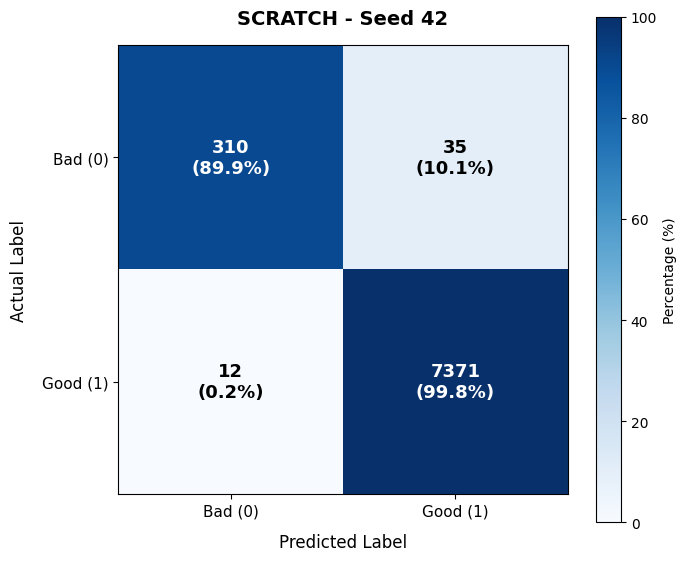

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/scratch_seed42_confusion_matrix.png


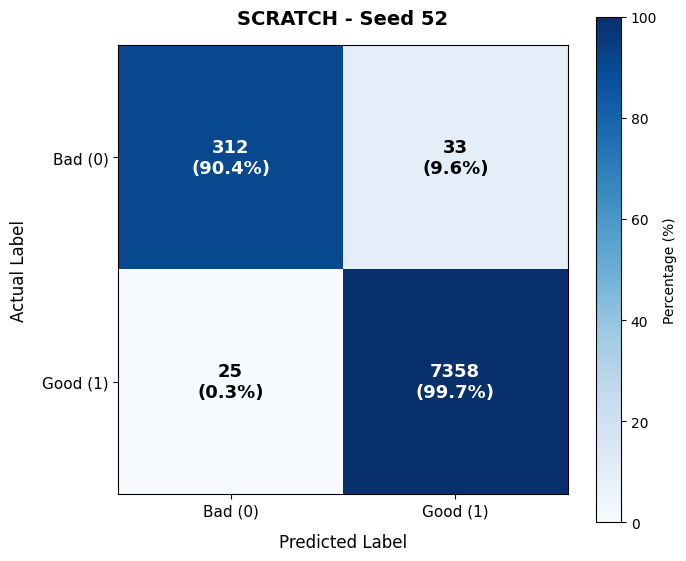

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/scratch_seed52_confusion_matrix.png


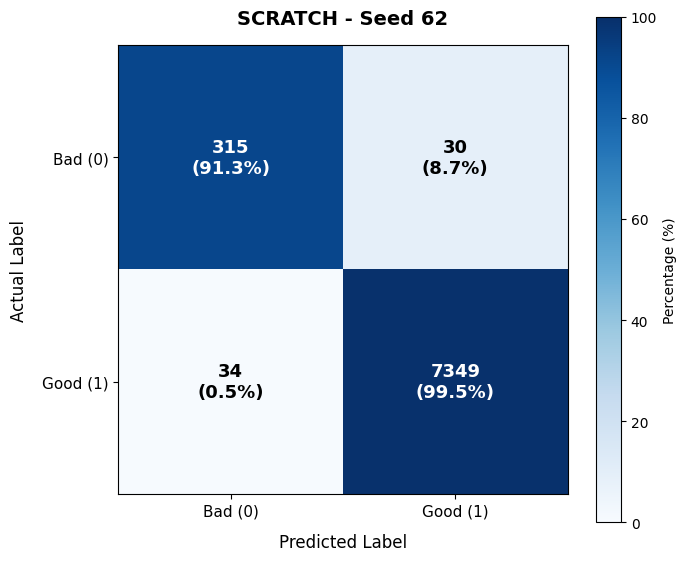

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/scratch_seed62_confusion_matrix.png


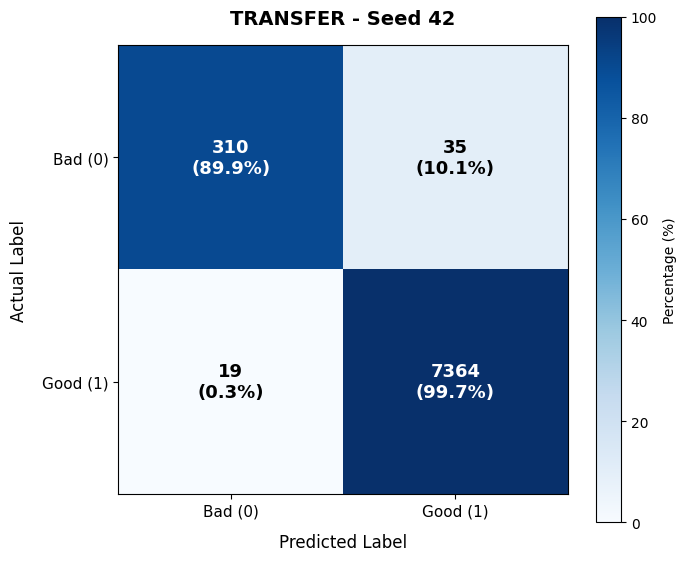

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/transfer_seed42_confusion_matrix.png


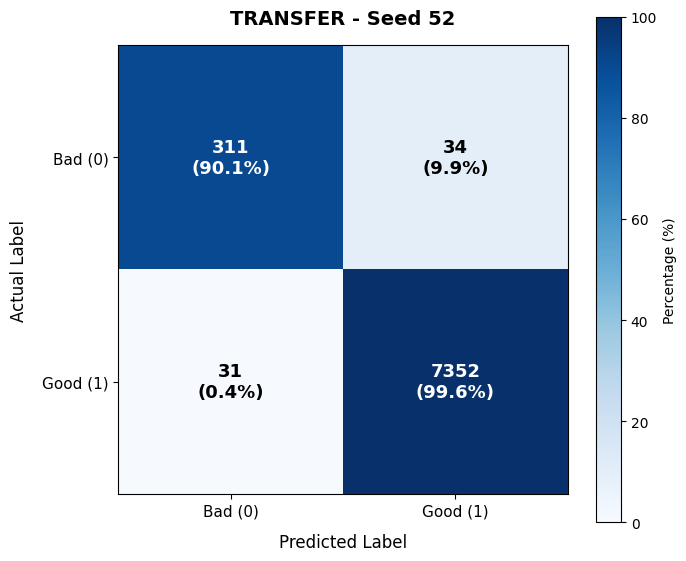

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/transfer_seed52_confusion_matrix.png


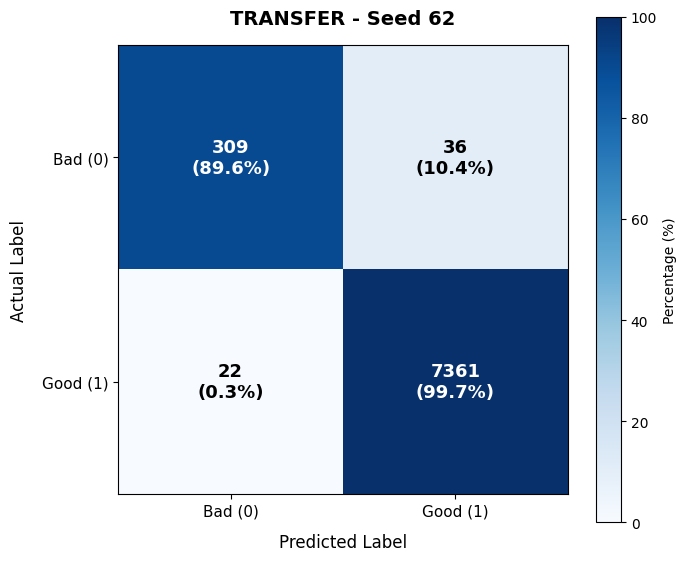

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/transfer_seed62_confusion_matrix.png


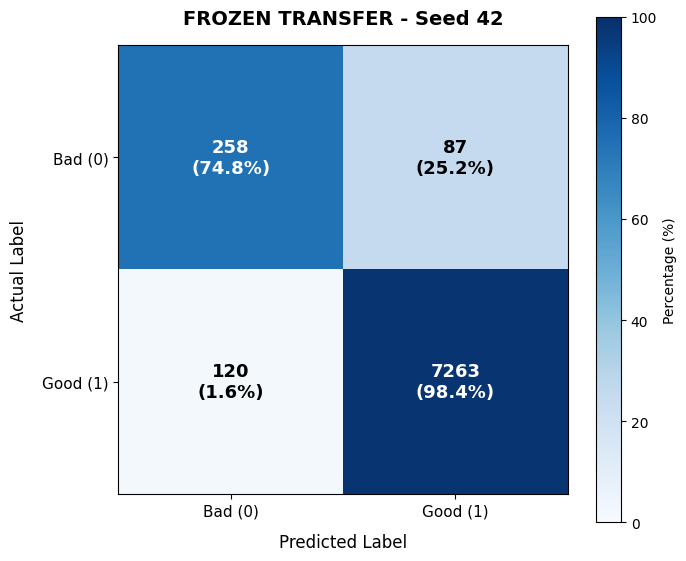

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/frozen_transfer_seed42_confusion_matrix.png


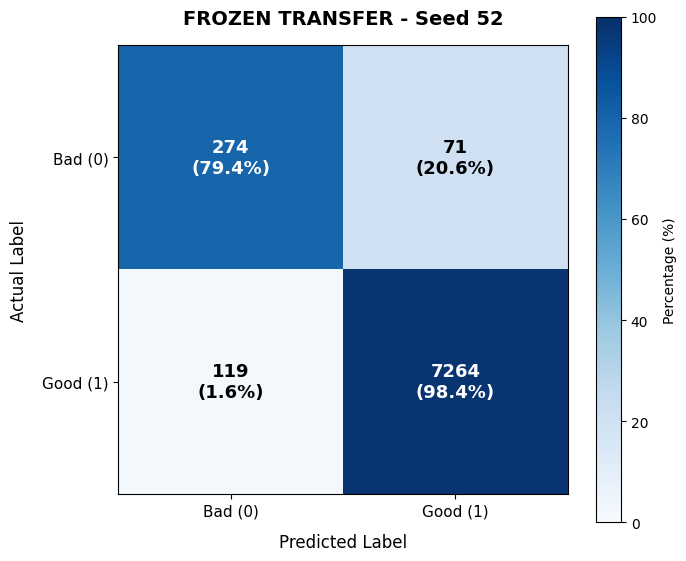

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/frozen_transfer_seed52_confusion_matrix.png


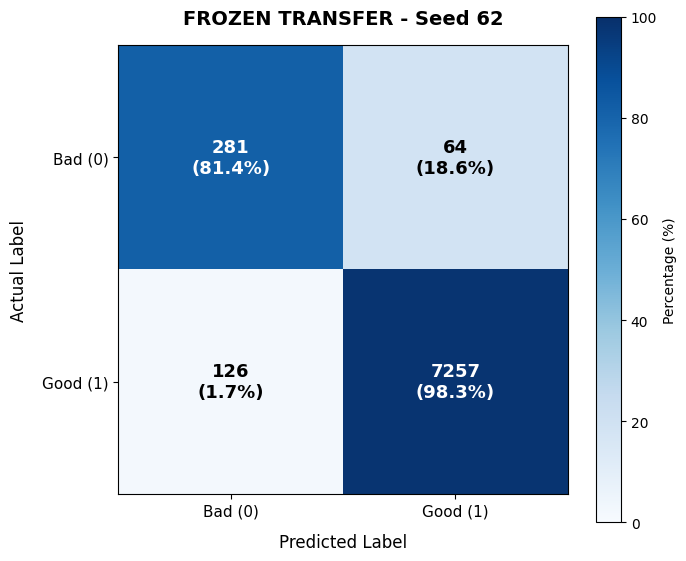

Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices/frozen_transfer_seed62_confusion_matrix.png

All 9 confusion matrices have been generated.


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

CONFUSION_DIR = E2_OUTPUT_DIR / "confusion_matrices"
CONFUSION_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["Bad (0)", "Good (1)"]

for config in CONFIGS:
    for seed in SEEDS:
        cm = np.asarray(
            test_confusion_matrices[(config, seed)],
            dtype=int
        )

        # Calculate percentage by actual class (row-wise)
        row_totals = cm.sum(axis=1, keepdims=True)
        cm_percent = np.divide(
            cm,
            row_totals,
            out=np.zeros_like(cm, dtype=float),
            where=row_totals != 0
        ) * 100

        # Create one independent figure
        fig, ax = plt.subplots(figsize=(7, 6))

        im = ax.imshow(cm_percent, cmap="Blues", vmin=0, vmax=100)

        # Add color bar
        cbar = fig.colorbar(im, ax=ax)
        cbar.set_label("Percentage (%)")

        # Add count and percentage annotations
        threshold = 50

        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                value = cm_percent[i, j]
                text_color = "white" if value > threshold else "black"

                ax.text(
                    j, i,
                    f"{cm[i, j]}\n({value:.1f}%)",
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=13,
                    fontweight="bold"
                )

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(CLASS_NAMES, fontsize=11)
        ax.set_yticklabels(CLASS_NAMES, fontsize=11)

        ax.set_xlabel("Predicted Label", fontsize=12, labelpad=10)
        ax.set_ylabel("Actual Label", fontsize=12, labelpad=10)

        ax.set_title(
            f"{config.upper().replace('_', ' ')} - Seed {seed}",
            fontsize=14,
            fontweight="bold",
            pad=15
        )

        fig.tight_layout()

        # Save each matrix separately
        filename = f"{config}_seed{seed}_confusion_matrix.png"
        save_path = CONFUSION_DIR / filename

        fig.savefig(save_path, dpi=180, bbox_inches="tight")

        plt.show()
        plt.close(fig)

        print(f"Saved: {save_path}")

print("\nAll 9 confusion matrices have been generated.")

In [44]:
#Cell 41 – Export Evaluation Results.

import pandas as pd
from pathlib import Path

# Create output directory
RESULTS_DIR = E2_OUTPUT_DIR
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Export per-seed evaluation results
validation_csv = RESULTS_DIR / "validation_results_by_seed.csv"
test_csv = RESULTS_DIR / "test_results_by_seed.csv"

validation_df.to_csv(validation_csv, index=False)
test_df.to_csv(test_csv, index=False)

# Export mean and standard deviation summaries
validation_summary_csv = RESULTS_DIR / "validation_mean_std.csv"
test_summary_csv = RESULTS_DIR / "test_mean_std.csv"

validation_summary.to_csv(validation_summary_csv, index=False)
test_summary.to_csv(test_summary_csv, index=False)

print("Evaluation results exported successfully:")
print(validation_csv)
print(test_csv)
print(validation_summary_csv)
print(test_summary_csv)


Evaluation results exported successfully:
/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/validation_results_by_seed.csv
/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/test_results_by_seed.csv
/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/validation_mean_std.csv
/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/test_mean_std.csv


In [45]:
#Cell 42 – Export Confusion Matrices.
import numpy as np

CONFUSION_CSV_DIR = RESULTS_DIR / "confusion_matrices_csv"
CONFUSION_CSV_DIR.mkdir(parents=True, exist_ok=True)

for config in CONFIGS:
    for seed in SEEDS:
        cm = np.asarray(
            test_confusion_matrices[(config, seed)],
            dtype=int
        )

        cm_df = pd.DataFrame(
            cm,
            index=["Actual_Bad", "Actual_Good"],
            columns=["Predicted_Bad", "Predicted_Good"]
        )

        filename = f"{config}_seed{seed}_confusion_matrix.csv"
        save_path = CONFUSION_CSV_DIR / filename

        cm_df.to_csv(save_path)

        print(f"Saved: {save_path}")

print("\nAll 9 confusion matrices exported.")


Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/scratch_seed42_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/scratch_seed52_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/scratch_seed62_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/transfer_seed42_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/transfer_seed52_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/transfer_seed62_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/frozen_transfer_seed42_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/confusion_matrices_csv/frozen_transfer_seed52_confusion_matrix.csv
Saved: /content/drive/MyDrive/UIT/MXH/ynhi211

In [46]:
#Cell 43 – Save Experiment Configuration.

import json

experiment_config = {
    "experiment": "E2_Honduras_Transfer_Learning",
    "task": "Bad_vs_Good_Account_Classification",

    "dataset": {
        "name": "Honduras",
        "total_accounts_before_filtering": 224685,
        "primary_cohort": "Accounts with selected_tweet_count > 0",
        "primary_cohort_size": 46824,
        "label_mapping": {
            "0": "Bad",
            "1": "Good"
        },
        "split": {
            "train": {
                "Bad": 1209,
                "Good": 34246,
                "Total": 35455
            },
            "validation": {
                "Bad": 172,
                "Good": 3469,
                "Total": 3641
            },
            "test": {
                "Bad": 345,
                "Good": 7383,
                "Total": 7728
            }
        }
    },

    "input": {
        "feature": "Honduras Tweet Embedding",
        "dimension": 384,
        "embedding_model": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
    },

    "architecture": {
        "tweet_branch": [
            "Linear(384, 128)",
            "LayerNorm(128)",
            "GELU",
            "Dropout(0.3)"
        ],
        "classifier": "Linear(128, 2)"
    },

    "configurations": [
        "scratch",
        "transfer",
        "frozen_transfer"
    ],

    "transfer_source": {
        "checkpoint": "best_model.pt",
        "sha256": "219c21ca894c6ea4bcd8a4ac009f0383880892aa0df665795e0ef8f880ce7394",
        "transferred_component": "E1 Tweet Branch only"
    },

    "training": {
        "seeds": SEEDS,
        "batch_size": 128,
        "optimizer": "AdamW",
        "learning_rate": 0.0002,
        "weight_decay": 0.01,
        "max_epochs": 30,
        "early_stopping_patience": 5,
        "loss": "Weighted Cross Entropy",
        "class_weights": class_weights.detach().cpu().tolist(),
        "checkpoint_selection": "Highest Validation Macro-F1; tie-break by lower Validation Loss"
    },

    "evaluation": {
        "validation": "Used for checkpoint selection",
        "test": "Used for final evaluation only",
        "metrics": [
            "Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Bad Precision",
            "Bad Recall",
            "Bad F1",
            "Bad Average Precision"
        ],
        "positive_class_for_bad_metrics": 0,
        "summary": "Mean and sample standard deviation (ddof=1) across 3 seeds"
    },

    "scope_limitation": (
        "Results apply only to accounts with at least one selected tweet, "
        "not all 224685 Honduras accounts."
    )
}

config_path = RESULTS_DIR / "e2_experiment_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(experiment_config, f, indent=4, ensure_ascii=False)

print(f"Experiment configuration saved: {config_path}")

Experiment configuration saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/e2_experiment_config.json


In [47]:
#Cell 44 – E2 Artifact Audit.

artifact_rows = []

for config in CONFIGS:
    for seed in SEEDS:
        files_to_check = {
            "checkpoint": E2_CHECKPOINT_DIR / f"{config}_seed{seed}_best.pt",
            "history": RESULTS_DIR / f"{config}_seed{seed}_history.json",
            "confusion_matrix_png": CONFUSION_DIR / f"{config}_seed{seed}_confusion_matrix.png",
            "confusion_matrix_csv": CONFUSION_CSV_DIR / f"{config}_seed{seed}_confusion_matrix.csv"
        }

        for artifact_type, path in files_to_check.items():
            artifact_rows.append({
                "configuration": config,
                "seed": seed,
                "artifact": artifact_type,
                "exists": path.exists(),
                "size_kb": round(path.stat().st_size / 1024, 2) if path.exists() else None,
                "path": str(path)
            })

artifact_df = pd.DataFrame(artifact_rows)

display(artifact_df)

missing_artifacts = artifact_df[~artifact_df["exists"]]

print("\n===== ARTIFACT AUDIT SUMMARY =====")
print(f"Total artifacts checked: {len(artifact_df)}")
print(f"Existing artifacts: {artifact_df['exists'].sum()}")
print(f"Missing artifacts: {len(missing_artifacts)}")

if len(missing_artifacts) == 0:
    print("\nSUCCESS: All E2 artifacts are available.")
else:
    print("\nWARNING: Some artifacts are missing.")
    display(missing_artifacts)

# Save audit report
audit_path = RESULTS_DIR / "e2_artifact_audit.csv"
artifact_df.to_csv(audit_path, index=False)

print(f"\nAudit report saved: {audit_path}")

,configuration,seed,artifact,exists,size_kb,path
0,scratch,42,checkpoint,True,592.11,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
1,scratch,42,history,True,7.59,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
2,scratch,42,confusion_matrix_png,True,69.70,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
3,scratch,42,confusion_matrix_csv,True,0.07,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
4,scratch,52,checkpoint,True,592.38,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
5,scratch,52,history,True,4.80,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
6,scratch,52,confusion_matrix_png,True,70.67,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
7,scratch,52,confusion_matrix_csv,True,0.07,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
8,scratch,62,checkpoint,True,592.38,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...
9,scratch,62,history,True,4.29,/content/drive/MyDrive/UIT/MXH/ynhi2111/e2/res...



===== ARTIFACT AUDIT SUMMARY =====
Total artifacts checked: 36
Existing artifacts: 36
Missing artifacts: 0

SUCCESS: All E2 artifacts are available.

Audit report saved: /content/drive/MyDrive/UIT/MXH/ynhi2111/e2/results/e2_artifact_audit.csv
